# Khám phá và Trực quan hóa Dữ liệu (Exploratory Data Analysis)
**Dự án:** Hệ thống Nhận diện Ý định Hội thoại NPC trong Game Nhập vai (Vietnamese RPG Intent Classification)  
**Nhãn mục tiêu (5 lớp):** `GREETING` (Chào hỏi) · `TRADE` (Giao dịch) · `INFO` (Hỏi thông tin/Nhiệm vụ) · `HOSTILE` (Công kích/Khiêu khích) · `UNKNOWN` (Ngoài luồng/Nhiễu)

---

### Mục tiêu của Notebook
1. **Đảm bảo tính độc lập (Standalone-Ready)**: Tự động nhận diện dữ liệu từ dự án cục bộ, tự động tải từ GitHub nếu người dùng tải lẻ file `.ipynb`, hoặc kích hoạt bộ sinh dữ liệu dự phòng khi ngoại tuyến.
2. **Đánh giá chất lượng gán nhãn thủ công (`dataset_ver1.csv`)**: Đo lường mức độ đồng thuận giữa hai người gán nhãn (*Cohen's Kappa*) và phân tích các câu hội thoại nhập nhằng ngữ nghĩa.
3. **Kiểm định phân phối & tính chống rò rỉ dữ liệu (`train.json` & `test.json`)**: Đánh giá cân bằng lớp (*Class Balance*) và kiểm chứng quy trình chia tách *Zero-Leakage*.
4. **Phân tích đặc trưng ngôn ngữ game thủ Việt**: Khảo sát phân phối độ dài câu, tỷ lệ mất dấu tiếng Việt, mật độ *teencode* / từ viết tắt và các mẫu gây nhiễu (*Hard Negatives*).
5. **Khám phá không gian vector `TF-IDF` (2.000 chiều)**: Phân tích độ thưa (*Sparsity*), trích xuất Top *N-grams* đặc trưng từng ý định và trực quan hóa giảm chiều 2D bằng `TruncatedSVD`.

## 0. Khởi tạo Môi trường & Cơ chế Tự động Cấp phát Dữ liệu (3 Tầng)
Ô mã dưới đây kiểm tra thư viện và tự động chuẩn bị dữ liệu theo thứ tự ưu tiên:
1. **Tầng 1 (Local Repo)**: Tìm thư mục `data/` ngay trong kho mã nguồn dự án.
2. **Tầng 2 (GitHub Raw Fetch)**: Nếu người dùng chỉ tải riêng lẻ file `.ipynb` này (ví dụ mở trên Google Colab), hệ thống tự tải các file dữ liệu chuẩn từ nhánh `main` của kho lưu trữ GitHub.
3. **Tầng 3 (Offline Fallback)**: Nếu không có kết nối mạng, hệ thống tự động sinh tập dữ liệu RPG tiếng Việt chuẩn *Zero-Leakage* để toàn bộ các bước phân tích và biểu đồ bên dưới vẫn chạy trọn vẹn.

In [1]:
import importlib.util
import json
import os
import re
import subprocess
import sys
import unicodedata
import urllib.request
import warnings
from collections import Counter
from pathlib import Path

warnings.filterwarnings("ignore")

# 1. Tự động kiểm tra và cài đặt thư viện thiếu (hữu ích khi chạy lẻ trên Colab / máy mới)
REQUIRED_PACKAGES = {"numpy": "numpy", "pandas": "pandas", "scipy": "scipy", "sklearn": "scikit-learn", "matplotlib": "matplotlib"}
missing_pkgs = [pip_name for mod, pip_name in REQUIRED_PACKAGES.items() if importlib.util.find_spec(mod) is None]
if missing_pkgs:
    print(f"[Setup] Đang cài đặt các gói thư viện còn thiếu: {missing_pkgs} ...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing_pkgs])

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import cohen_kappa_score, confusion_matrix

plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "Segoe UI", "Arial"]
plt.rcParams["axes.unicode_minus"] = False

INTENT_NAMES = ["GREETING", "TRADE", "INFO", "HOSTILE", "UNKNOWN"]
INTENT_COLORS = {"GREETING": "#2ca02c", "TRADE": "#1f77b4", "INFO": "#ff7f0e", "HOSTILE": "#d62728", "UNKNOWN": "#9467bd"}
GITHUB_RAW_BASE = "https://raw.githubusercontent.com/DianLiberos/intent-classification/main"

def _synthesize_offline_rpg_dataset(data_dir: Path, n_train_seeds: int = 80, n_test_seeds: int = 30):
    """Tier 3 Fallback: Sinh bộ dữ liệu RPG tiếng Việt chuẩn Zero-Leakage khi chạy lẻ hoàn toàn Offline."""
    import random, re, unicodedata, csv
    rng = random.Random(42)
    data_dir.mkdir(parents=True, exist_ok=True)

    vocab = {
        "pronoun": ["tôi", "tui", "mình", "em", "anh", "tại hạ", "kẻ lữ hành này", "tao"],
        "npc": ["ông chủ", "chủ tiệm", "shop", "lão bản", "thợ rèn", "thương nhân", "trưởng làng", "tiền bối"],
        "greet": ["xin chào", "chào", "hello", "hi", "alo", "kính chào", "bái kiến", "hú"],
        "item": ["kiếm sắt", "đại đao", "cung gỗ", "giáp sắt", "bình máu", "bình mana", "đá cường hóa", "quặng sắt", "vảy rồng"],
        "currency": ["vàng", "bạc", "xu", "kim cương", "gold", "linh thạch"],
        "buy": ["mua", "lấy", "tậu", "chốt", "sắm", "đổi lấy"],
        "loc": ["rừng phía bắc", "hang nhện", "đầm lầy tử thần", "làng tân thủ", "tháp ma thuật", "hầm ngục tối"],
        "monster": ["goblin", "slime", "rồng lửa", "quỷ vương", "sói xám", "nhện độc"],
        "quest": ["nhiệm vụ", "quest", "ủy thác", "bản đồ kho báu", "mật thư"],
        "insult": ["đồ phế vật", "thằng lừa đảo", "đồ ăn hại", "lão già dịch", "đồ hút máu"],
        "hostile": ["đập nát tiệm", "đốt quán", "chém chết", "cướp sạch", "san phẳng chỗ này"],
        "ood": ["bitcoin", "trà sữa trân châu", "code Python", "iPhone 16", "giá xăng hôm nay", "Ngoại hạng Anh", "mật khẩu wifi"],
    }

    train_tpl = {
        "GREETING": [
            "{greet} {npc}, chúc một ngày tốt lành!",
            "{npc} ơi, {pronoun} mới tới vùng này, {greet} nhé!",
            "Lâu quá không gặp {npc}, dạo này vẫn khỏe chứ?",
            "{greet} {npc}, {pronoun} vừa đi săn ở {loc} về ghé chào một tiếng!",
        ],
        "TRADE": [
            "{npc} ơi, bán cho {pronoun} một cái {item} tính bằng {currency} với.",
            "Món {item} này giá bao nhiêu {currency} vậy {npc}?",
            "{pronoun} muốn {buy} ít {item}, mở kho hàng xem thử nào!",
            "Giảm giá món {item} chút đi {npc}, {pronoun} {buy} liền trả đủ {currency}!",
        ],
        "INFO": [
            "{npc} cho {pronoun} hỏi đường đi tới {loc} ở hướng nào vậy?",
            "Làm sao để hạ gục con {monster} ở {loc} thế {npc}?",
            "Ở đây có {quest} nào mới cho {pronoun} nhận không {npc}?",
            "Đánh con {monster} ở {loc} thì rớt nguyên liệu {item} nào vậy?",
        ],
        "HOSTILE": [
            "Đồ {insult}, hôm nay {pronoun} sẽ {hostile} của mày!",
            "Bán {item} giá cắt cổ thế à, định cướp cạn hả {insult}?",
            "Cút ngay trước khi tao nổi điên tới {hostile} đồ {insult}!",
            "Nhìn mặt {npc} ngứa mắt thật sự, bước ra đây solo đi {insult}!",
        ],
        "UNKNOWN": [
            "{npc} ơi, hôm nay giá {ood} ngoài đời là bao nhiêu tiền vậy?",
            "Chỉ giúp {pronoun} cách học {ood} sao cho nhanh giỏi với!",
            "Quanh đây có quán nào bán {ood} giao tận nhà không nhỉ?",
            "Đổi 1000 {currency} trong game lấy {ood} ngoài đời thật được không shop?",
        ],
    }

    test_tpl = {
        "GREETING": [
            "Ồ {npc} vẫn canh tiệm đấy à, {greet} buổi sáng nha!",
            "Một ngày bình an nhé {npc}, {pronoun} ghé qua điểm danh cái!",
        ],
        "TRADE": [
            "Thanh toán cho {pronoun} món {item} bằng {currency} lẹ đi {npc}!",
            "Có nhận trao đổi {item} cũ bù thêm {currency} lấy đồ mới không shop?",
        ],
        "INFO": [
            "Bí kíp nào vượt ải {loc} mà không bị {monster} đánh bại vậy {npc}?",
            "Ai là người giao {quest} thám hiểm vùng {loc} hả {npc}?",
        ],
        "HOSTILE": [
            "Tiệm rách nát bán toàn {item} dỏm, dẹp tiệm đi đồ {insult}!",
            "Nói thêm câu nữa là tao {hostile} ngay tại chỗ đấy {insult}!",
        ],
        "UNKNOWN": [
            "Tư vấn giùm {pronoun} có nên đầu tư vào {ood} năm nay không?",
            "Ngoài đời đang bận {ood} mà tự nhiên vô game hỏi {npc} làm chi không biết!",
        ],
    }

    def strip_accents(s: str) -> str:
        s = re.sub(r"[đ]", "d", re.sub(r"[Đ]", "D", s))
        return "".join(c for c in unicodedata.normalize("NFD", s) if unicodedata.category(c) != "Mn")

    def to_teencode(s: str) -> str:
        out = s.lower()
        subs = [(r"\bkhông\b", "ko"), (r"\bbao nhiêu\b", "bn"), (r"\bông chủ\b", "shop"),
                (r"\btôi\b", "tui"), (r"\bvậy\b", "z"), (r"\bvới\b", "vs"), (r"\bđược\b", "dc")]
        for pat, rep in subs:
            if rng.random() < 0.75:
                out = re.sub(pat, rep, out)
        return re.sub(r"[!?.]+$", "", out).strip()

    def fill(tpl: str) -> str:
        out = tpl
        for k in re.findall(r"\{(\w+)\}", tpl):
            out = out.replace(f"{{{k}}}", rng.choice(vocab[k]), 1)
        return out

    def make_split(tpl_map, seeds_per_intent, seen_norm):
        rows = []
        for intent, tpls in tpl_map.items():
            cnt, tries = 0, 0
            while cnt < seeds_per_intent and tries < seeds_per_intent * 40:
                tries += 1
                seed = fill(rng.choice(tpls))
                key = strip_accents(seed.lower())
                if key in seen_norm:
                    continue
                seen_norm.add(key)
                cnt += 1
                v1 = seed
                v2 = to_teencode(seed)
                v3 = strip_accents(v2)
                v4 = f"ê {v2} nha"
                for v in (v1, v2, v3, v4):
                    rows.append({"text": v, "intent": intent})
        rng.shuffle(rows)
        return rows

    seen = set()
    train_rows = make_split(train_tpl, n_train_seeds, seen)
    test_rows = make_split(test_tpl, n_test_seeds, seen)
    full_rows = train_rows + test_rows

    (data_dir / "train.json").write_text(json.dumps(train_rows, ensure_ascii=False, indent=2), encoding="utf-8")
    (data_dir / "test.json").write_text(json.dumps(test_rows, ensure_ascii=False, indent=2), encoding="utf-8")
    (data_dir / "dataset_full.json").write_text(json.dumps(full_rows, ensure_ascii=False, indent=2), encoding="utf-8")

    intents_list = list(train_tpl.keys())
    with open(data_dir / "dataset_ver1.csv", "w", encoding="utf-8", newline="") as f:
        writer = csv.writer(f)
        writer.writerow(["id", "text", "annonator_1", "annonator_2", "final intent"])
        for idx, row in enumerate(train_rows[:200], start=1):
            a1 = row["intent"]
            a2 = a1 if rng.random() > 0.08 else rng.choice(intents_list)
            writer.writerow([idx, row["text"], a1, a2, row["intent"]])

    return train_rows, test_rows


def resolve_eda_data() -> tuple[Path, str]:
    force_standalone = os.environ.get("FORCE_STANDALONE_TEST", "0") == "1"
    force_offline = os.environ.get("FORCE_OFFLINE_FALLBACK", "0") == "1"

    # Tầng 1: Quét thư mục dự án cục bộ
    if not force_standalone:
        cwd = Path.cwd().resolve()
        candidates = [cwd, cwd.parent, cwd.parent.parent, cwd / "intent-classification"]
        for root in candidates:
            if (root / "data" / "train.json").exists() and (root / "data" / "test.json").exists():
                return root / "data", f"Tầng 1 - Dữ liệu cục bộ dự án ({root / 'data'})"

    # Thư mục làm việc độc lập khi tải lẻ file .ipynb
    ws_data = Path.cwd().resolve() / "standalone_workspace" / "data"
    ws_data.mkdir(parents=True, exist_ok=True)
    needed_files = ["dataset_ver1.csv", "train.json", "test.json", "dataset_full.json"]

    if all((ws_data / fn).exists() for fn in needed_files) and not force_offline:
        return ws_data, f"Tầng 2 - Cache dữ liệu độc lập ({ws_data})"

    # Tầng 2: Tự động tải từ GitHub Raw
    if not force_offline:
        try:
            print("[Bootstrap] Không tìm thấy kho dự án cục bộ. Đang tải dữ liệu từ GitHub...")
            for fn in needed_files:
                url = f"{GITHUB_RAW_BASE}/data/{fn}"
                req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
                with urllib.request.urlopen(req, timeout=12) as resp:
                    (ws_data / fn).write_bytes(resp.read())
                print(f"  + Đã tải: {fn} ({(ws_data / fn).stat().st_size / 1024:.1f} KB)")
            return ws_data, f"Tầng 2 - Tải tự động từ GitHub ({ws_data})"
        except Exception as err:
            print(f"[Bootstrap] Không thể tải từ GitHub ({err}). Chuyển sang Tầng 3 (Offline Fallback)...")

    # Tầng 3: Sinh dữ liệu dự phòng ngoại tuyến
    _synthesize_offline_rpg_dataset(ws_data)
    return ws_data, f"Tầng 3 - Dữ liệu RPG giả lập Offline ({ws_data})"


DATA_DIR, DATA_SOURCE_MODE = resolve_eda_data()
print(f"✅ Nguồn dữ liệu đang sử dụng: {DATA_SOURCE_MODE}")

✅ Nguồn dữ liệu đang sử dụng: Tầng 1 - Dữ liệu cục bộ dự án (D:\project may hoc\intent-classification\data)


## 1. Tổng quan Cấu trúc & Tính toàn vẹn của Bộ Dữ liệu
Dự án bao gồm quá trình phát triển dữ liệu qua hai giai đoạn:
- **Giai đoạn khởi tạo thủ công (`dataset_ver1.csv`)**: Các mẫu câu hội thoại thực tế được người thật biên soạn và gán nhãn độc lập bởi 2 người gán nhãn (*Annotator 1* & *Annotator 2*).
- **Giai đoạn mở rộng quy mô lớn chống rò rỉ (`train.json` & `test.json`)**: Mở rộng lên hơn 11.000 câu hội thoại đa nhân cách (lịch sự, cộc lốc, kiếm hiệp, hiện đại), kết hợp *Hard Negatives* và biến đổi nhiễu thực tế (bỏ dấu, *teencode*), chia tách nghiêm ngặt theo gốc câu (*Seed-level Split*) trước khi tăng cường dữ liệu.

In [2]:
with open(DATA_DIR / "train.json", "r", encoding="utf-8") as f:
    train_raw = json.load(f)
with open(DATA_DIR / "test.json", "r", encoding="utf-8") as f:
    test_raw = json.load(f)

df_train = pd.DataFrame(train_raw)
df_test = pd.DataFrame(test_raw)
df_seed = pd.read_csv(DATA_DIR / "dataset_ver1.csv")

overview_df = pd.DataFrame([
    {
        "Tập dữ liệu": "Seed thủ công (dataset_ver1.csv)",
        "Số mẫu": len(df_seed),
        "Số cột": df_seed.shape[1],
        "Giá trị khuyết (Null)": int(df_seed.isna().sum().sum()),
        "Số câu duy nhất": df_seed["text"].nunique(),
    },
    {
        "Tập dữ liệu": "Tập Huấn luyện (train.json)",
        "Số mẫu": len(df_train),
        "Số cột": df_train.shape[1],
        "Giá trị khuyết (Null)": int(df_train.isna().sum().sum()),
        "Số câu duy nhất": df_train["text"].nunique(),
    },
    {
        "Tập dữ liệu": "Tập Kiểm thử (test.json)",
        "Số mẫu": len(df_test),
        "Số cột": df_test.shape[1],
        "Giá trị khuyết (Null)": int(df_test.isna().sum().sum()),
        "Số câu duy nhất": df_test["text"].nunique(),
    },
])

print("=== TỔNG QUAN CÁC TẬP DỮ LIỆU TRONG DỰ ÁN ===")
print(overview_df.to_string(index=False))

print("\n=== VÍ DỤ MẪU HỘI THOẠI ĐẶC TRƯNG THEO TỪNG Ý ĐỊNH (TẬP TRAIN) ===")
sample_rows = []
for intent in INTENT_NAMES:
    examples = df_train[df_train["intent"] == intent]["text"].head(2).tolist()
    for ex in examples:
        sample_rows.append({"Nhãn (Intent)": intent, "Câu hội thoại của người chơi": ex})
pd.DataFrame(sample_rows)

=== TỔNG QUAN CÁC TẬP DỮ LIỆU TRONG DỰ ÁN ===
                     Tập dữ liệu  Số mẫu  Số cột  Giá trị khuyết (Null)  Số câu duy nhất
Seed thủ công (dataset_ver1.csv)     250       5                      0              250
     Tập Huấn luyện (train.json)    9215       2                      0             9214
        Tập Kiểm thử (test.json)    2000       2                      0             2000

=== VÍ DỤ MẪU HỘI THOẠI ĐẶC TRƯNG THEO TỪNG Ý ĐỊNH (TẬP TRAIN) ===


,Nhãn (Intent),Câu hội thoại của người chơi
0,GREETING,"kính chào thầy pháp, mik vừa đi săn ở bến cảng về ghé chào ông một tiếng"
1,GREETING,"chào đại sư, anh vừa đi săn ở sa mạc lửa về ghé chào ông một tiếng!"
2,TRADE,giup anh day cuong hoa cai mu phap su nay len cap vs cac ha
3,TRADE,"dat cung dc, mua luon cay no than nay, goi lai nhanh len"
4,INFO,con vua hải tặc thường xuất hiện vào thời gian nào trong ngày vậy các hạ
5,INFO,"tiểu đệ bị kẹt ở quest này rồi, lão bản gợi ý cách giải với!"
6,HOSTILE,"vl, tin tao goi anh em toi bam vam luon khong ha anh chu shop?"
7,HOSTILE,nè m là cái thá chi mà dám lên mặt dạy đời t hả thằng cặn bã vậy
8,UNKNOWN,chi duong cho bon toa di mua xe sh ve an chong doi cai coi!
9,UNKNOWN,Làm nhiệm vụ hàng ngày gì để qua môn cấu trúc dữ liệu đạt điểm A bây giờ hả ông chủ?


## 2. Phân tích Độ đồng thuận Gán nhãn Thủ công (*Inter-Annotator Agreement*)
Trên tập `dataset_ver1.csv`, mỗi câu thoại được gán nhãn độc lập bởi `annonator_1` và `annonator_2` trước khi chốt `final intent`. Chỉ số **Cohen's Kappa ($\kappa$)** giúp định lượng mức độ nhất quán vượt trên sự trùng hợp ngẫu nhiên:

$$\kappa = \frac{p_o - p_e}{1 - p_e}$$

Trong đó $p_o$ là tỷ lệ đồng thuận quan sát được và $p_e$ là xác suất đồng thuận ngẫu nhiên kỳ vọng. Những câu bất đồng giữa hai người gán nhãn cũng chính là manh mối quan trọng chỉ ra vùng ranh giới mờ giữa các ý định (ví dụ giữa `TRADE` và `INFO`).

Tổng số mẫu gán nhãn đôi: 250 mẫu
Tỷ lệ đồng thuận tuyệt đối (Exact Agreement): 92.40%
Hệ số Cohen's Kappa (κ): 0.9050 -> Rất cao (Almost Perfect)

Các mẫu bất đồng tiêu biểu giữa 2 người gán nhãn (19 mẫu tổng cộng):


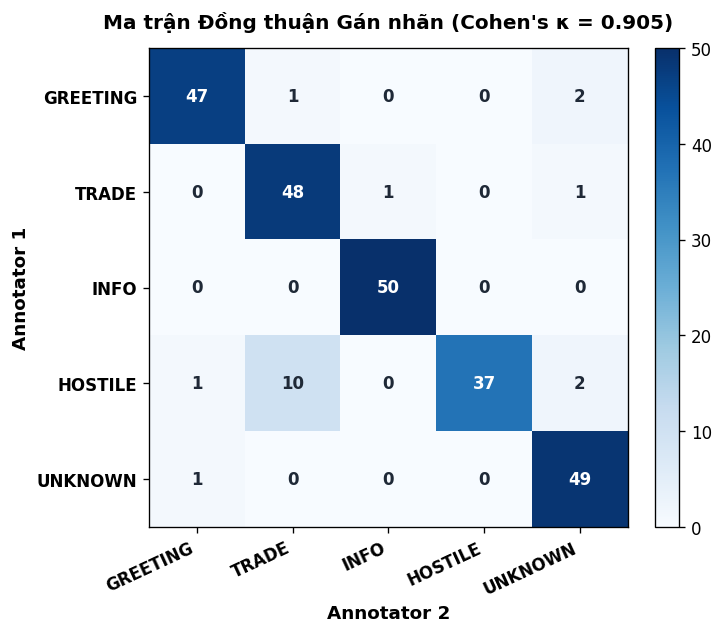

,id,text,annonator_1,annonator_2,final intent
2,3,shop còn online ko,GREETING,TRADE,GREETING
11,12,Có loại thuốc hồi HP xịn hơn không?,TRADE,INFO,TRADE
39,40,"ong oi, tui dan game thu",GREETING,UNKNOWN,UNKNOWN
40,41,ban do dom qua,HOSTILE,TRADE,HOSTILE
53,54,bao cao admin gian lan,HOSTILE,UNKNOWN,UNKNOWN
56,57,"shop ơii, cho em chao 1 cái",GREETING,UNKNOWN,GREETING
79,80,shop lừa đảo hả,HOSTILE,TRADE,HOSTILE
80,81,Mắc vậy bán cho ma à?,HOSTILE,TRADE,HOSTILE
95,96,bán mắc thế ai chịu nổi,HOSTILE,TRADE,HOSTILE
113,114,shop scam à,HOSTILE,TRADE,HOSTILE


In [3]:
a1 = df_seed["annonator_1"].str.strip()
a2 = df_seed["annonator_2"].str.strip()
final_lbl = df_seed["final intent"].str.strip()

exact_agree = (a1 == a2).mean() * 100
kappa = cohen_kappa_score(a1, a2, labels=INTENT_NAMES)

print(f"Tổng số mẫu gán nhãn đôi: {len(df_seed)} mẫu")
print(f"Tỷ lệ đồng thuận tuyệt đối (Exact Agreement): {exact_agree:.2f}%")
print(f"Hệ số Cohen's Kappa (κ): {kappa:.4f} -> {'Rất cao (Almost Perfect)' if kappa >= 0.8 else 'Khá tốt (Substantial)'}")

cm_annot = confusion_matrix(a1, a2, labels=INTENT_NAMES)

fig, ax = plt.subplots(figsize=(6.8, 5.4))
im = ax.imshow(cm_annot, cmap="Blues")
ax.set_xticks(range(len(INTENT_NAMES)), INTENT_NAMES, rotation=25, ha="right", fontweight="bold")
ax.set_yticks(range(len(INTENT_NAMES)), INTENT_NAMES, fontweight="bold")
ax.set_xlabel("Annotator 2", fontsize=11, fontweight="bold")
ax.set_ylabel("Annotator 1", fontsize=11, fontweight="bold")
ax.set_title(f"Ma trận Đồng thuận Gán nhãn (Cohen's κ = {kappa:.3f})", fontsize=12, fontweight="bold", pad=12)

for i in range(len(INTENT_NAMES)):
    for j in range(len(INTENT_NAMES)):
        val = cm_annot[i, j]
        color = "white" if val > cm_annot.max() * 0.55 else "#1f2937"
        ax.text(j, i, str(val), ha="center", va="center", color=color, fontweight="bold", fontsize=10)

plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

disagreements = df_seed[a1 != a2][["id", "text", "annonator_1", "annonator_2", "final intent"]].head(10)
print(f"\nCác mẫu bất đồng tiêu biểu giữa 2 người gán nhãn ({(a1 != a2).sum()} mẫu tổng cộng):")
disagreements

## 3. Phân phối Nhãn & Kiểm định Chống Rò rỉ Dữ liệu (*Zero-Leakage Audit*)
Trong phân loại đa lớp, mất cân bằng nhãn dễ khiến mô hình thiên vị lớp đa số, còn hiện tượng rò rỉ dữ liệu (*Data Leakage* — cùng một câu gốc xuất hiện biến thể ở cả Train và Test) làm độ chính xác kiểm thử cao giả tạo. Ta tiến hành kiểm tra đồng thời phân phối 5 nhãn và tỷ lệ trùng lặp văn bản chuẩn hóa giữa `train.json` và `test.json`.

=== BẢNG PHÂN PHỐI NHÃN TRÊN TẬP TRAIN VÀ TẬP TEST ===
          Train (Mẫu)  Train (%)  Test (Mẫu)  Test (%)
intent                                                
GREETING         1859      20.17         400      20.0
TRADE            1829      19.85         400      20.0
INFO             1844      20.01         400      20.0
HOSTILE          1838      19.95         400      20.0
UNKNOWN          1845      20.02         400      20.0

[Kiểm định Rò rỉ] Trùng khớp câu chính xác giữa Train & Test: 0 mẫu
[Kiểm định Rò rỉ] Trùng khớp sau khi bỏ dấu & ký tự đặc biệt: 0 mẫu (0.00% tập Test)


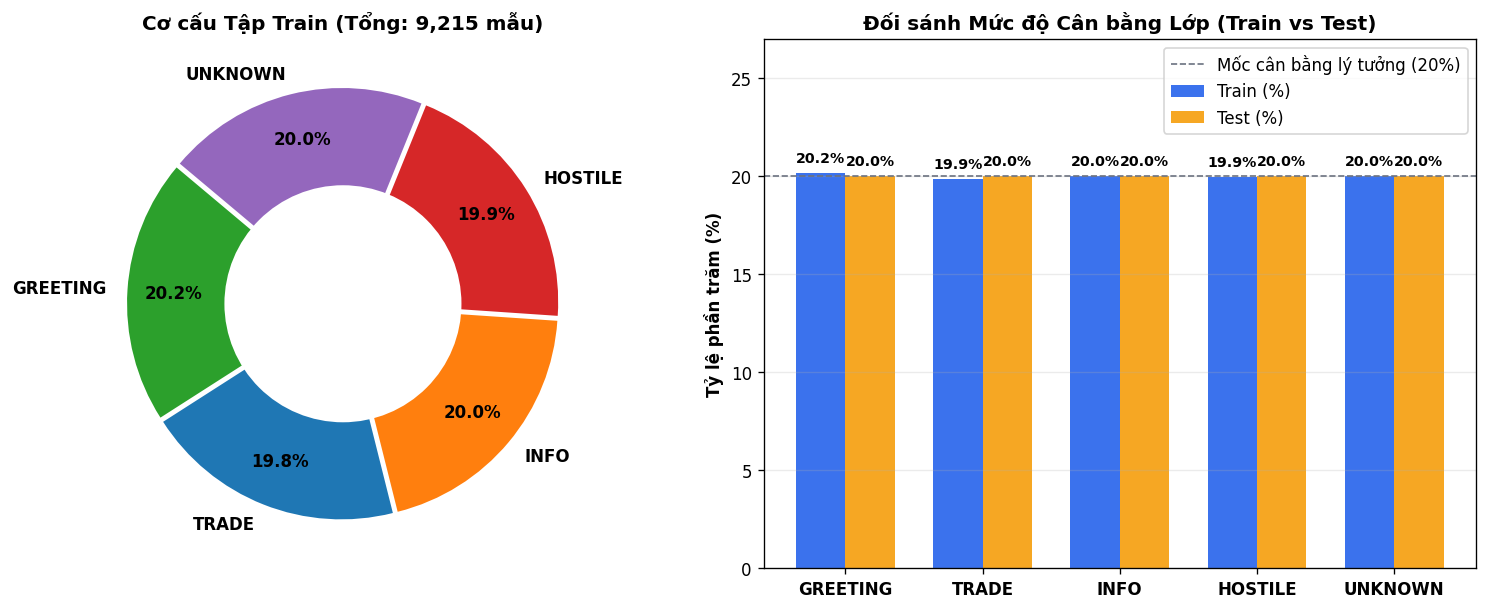

In [4]:
def normalize_for_leakage_check(text: str) -> str:
    s = re.sub(r"[đ]", "d", re.sub(r"[Đ]", "D", text.lower().strip()))
    s = "".join(c for c in unicodedata.normalize("NFD", s) if unicodedata.category(c) != "Mn")
    return re.sub(r"[^a-z0-9\s]", "", s).strip()

train_counts = df_train["intent"].value_counts().reindex(INTENT_NAMES)
test_counts = df_test["intent"].value_counts().reindex(INTENT_NAMES)

dist_table = pd.DataFrame({
    "Train (Mẫu)": train_counts,
    "Train (%)": (train_counts / len(df_train) * 100).round(2),
    "Test (Mẫu)": test_counts,
    "Test (%)": (test_counts / len(df_test) * 100).round(2),
})
print("=== BẢNG PHÂN PHỐI NHÃN TRÊN TẬP TRAIN VÀ TẬP TEST ===")
print(dist_table.to_string())

exact_overlap = len(set(df_train["text"].str.lower().str.strip()) & set(df_test["text"].str.lower().str.strip()))
norm_overlap = len(set(df_train["text"].map(normalize_for_leakage_check)) & set(df_test["text"].map(normalize_for_leakage_check)))
print(f"\n[Kiểm định Rò rỉ] Trùng khớp câu chính xác giữa Train & Test: {exact_overlap} mẫu")
print(f"[Kiểm định Rò rỉ] Trùng khớp sau khi bỏ dấu & ký tự đặc biệt: {norm_overlap} mẫu ({norm_overlap / len(df_test) * 100:.2f}% tập Test)")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.2))

# Biểu đồ Donut cho tập Train
wedges, texts, autotexts = ax1.pie(
    train_counts.values,
    labels=INTENT_NAMES,
    autopct="%1.1f%%",
    startangle=140,
    colors=[INTENT_COLORS[k] for k in INTENT_NAMES],
    pctdistance=0.78,
    explode=[0.02] * 5,
    textprops={"fontsize": 10, "weight": "bold"},
)
ax1.add_artist(plt.Circle((0, 0), 0.56, fc="white"))
ax1.set_title(f"Cơ cấu Tập Train (Tổng: {len(df_train):,} mẫu)", fontsize=12, fontweight="bold")

# Biểu đồ cột ghép so sánh tỷ lệ % Train vs Test
x = np.arange(len(INTENT_NAMES))
width = 0.36
b1 = ax2.bar(x - width / 2, dist_table["Train (%)"], width, label="Train (%)", color="#2563eb", alpha=0.9)
b2 = ax2.bar(x + width / 2, dist_table["Test (%)"], width, label="Test (%)", color="#f59e0b", alpha=0.9)
ax2.axhline(20.0, color="#6b7280", linestyle="--", linewidth=1, label="Mốc cân bằng lý tưởng (20%)")
ax2.set_xticks(x, INTENT_NAMES, fontweight="bold")
ax2.set_ylabel("Tỷ lệ phần trăm (%)", fontweight="bold")
ax2.set_ylim(0, 27)
ax2.set_title("Đối sánh Mức độ Cân bằng Lớp (Train vs Test)", fontsize=12, fontweight="bold")
ax2.legend(loc="upper right")
ax2.grid(axis="y", alpha=0.25)

for bars in (b1, b2):
    for bar in bars:
        ax2.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.4, f"{bar.get_height():.1f}%",
                 ha="center", va="bottom", fontsize=8.5, fontweight="bold")

plt.tight_layout()
plt.show()

## 4. Phân tích Đặc trưng Ngôn ngữ & Nhiễu Thực tế của Game thủ Việt
Người chơi trong môi trường chat trực tuyến hiếm khi gõ tiếng Việt chuẩn chỉnh. Dữ liệu bao gồm nhiều dạng biến thể:
- **Câu có dấu tiếng Việt đầy đủ** (*Clean / Diacritic Vietnamese*).
- **Câu gõ tắt không dấu hoàn toàn** (khi tắt bộ gõ Unikey trong lúc chiến đấu).
- **Câu chứa *Teencode* / Tiếng lóng game thủ** (`ko`, `dc`, `bn`, `vs`, `mik`, `tui`, `nv`, `vcl`, `shop`...).

Ta bóc tách các đặc trưng này trên tập huấn luyện để hiểu rõ thách thức đối với bộ trích xuất đặc trưng từ vựng.

=== THỐNG KÊ ĐỘ DÀI CÂU THEO TỪNG Ý ĐỊNH ===
         word_count                char_len                
               mean median min max     mean median min  max
intent                                                     
GREETING       10.3   10.0   1  23     43.5   44.0   4   93
TRADE          13.7   14.0   3  21     57.3   61.0  12   89
INFO           15.0   16.0   4  23     63.9   68.0  15  104
HOSTILE        14.9   16.0   2  24     59.6   64.0   9   94
UNKNOWN        13.8   15.0   1  23     59.3   63.0   7   96


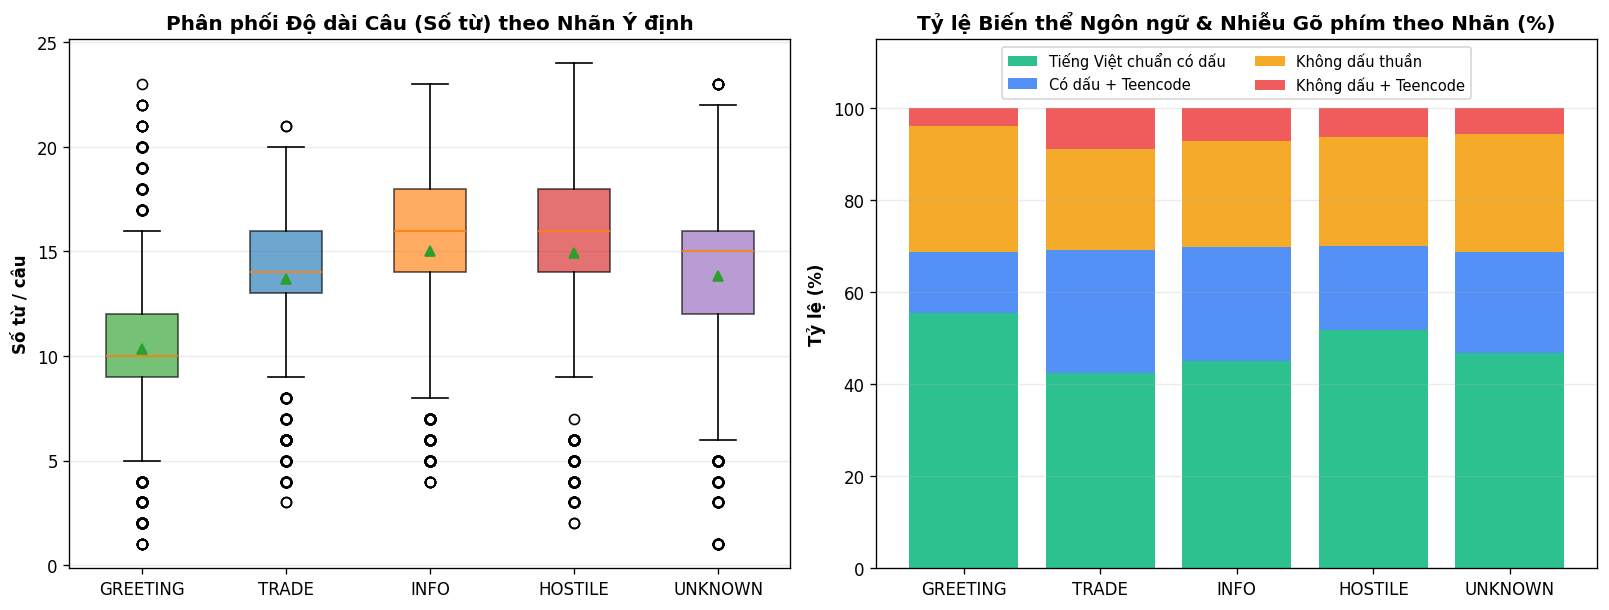

In [5]:
VN_ACCENT_REGEX = re.compile(r"[àáảãạăằắẳẵặâầấẩẫậđèéẻẽẹêềếểễệìíỉĩịòóỏõọôồốổỗộơờớởỡợùúủũụưừứửữựỳýỷỹỵ]", re.IGNORECASE)
TEENCODE_TOKENS = {"ko", "k", "khum", "hong", "dc", "đc", "dk", "bn", "nhiu", "bnhiu", "tui", "mik", "z", "zậy", "j", "rùi", "oy", "nv", "vs", "zới", "ntn", "vcl", "vl", "đm", "dm"}

df_eda = df_train.copy()
df_eda["char_len"] = df_eda["text"].str.len()
df_eda["word_count"] = df_eda["text"].str.split().str.len()
df_eda["has_diacritics"] = df_eda["text"].apply(lambda s: bool(VN_ACCENT_REGEX.search(s)))
df_eda["has_teencode"] = df_eda["text"].apply(
    lambda s: any(tok in TEENCODE_TOKENS for tok in re.findall(r"\w+", s.lower()))
)

def classify_style(row) -> str:
    if not row["has_diacritics"] and row["has_teencode"]:
        return "Không dấu + Teencode"
    if not row["has_diacritics"]:
        return "Không dấu thuần"
    if row["has_teencode"]:
        return "Có dấu + Teencode"
    return "Tiếng Việt chuẩn có dấu"

df_eda["text_style"] = df_eda.apply(classify_style, axis=1)

length_stats = df_eda.groupby("intent")[["word_count", "char_len"]].agg(["mean", "median", "min", "max"]).reindex(INTENT_NAMES).round(1)
print("=== THỐNG KÊ ĐỘ DÀI CÂU THEO TỪNG Ý ĐỊNH ===")
print(length_stats.to_string())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 5.2))

# Boxplot phân phối số từ theo từng Intent
box_data = [df_eda[df_eda["intent"] == it]["word_count"].values for it in INTENT_NAMES]
bp = ax1.boxplot(box_data, labels=INTENT_NAMES, patch_artist=True, showmeans=True)
for patch, it in zip(bp["boxes"], INTENT_NAMES):
    patch.set_facecolor(INTENT_COLORS[it])
    patch.set_alpha(0.65)
ax1.set_title("Phân phối Độ dài Câu (Số từ) theo Nhãn Ý định", fontsize=12, fontweight="bold")
ax1.set_ylabel("Số từ / câu", fontweight="bold")
ax1.grid(axis="y", alpha=0.25)

# Stacked bar tỷ lệ kiểu ngôn ngữ / nhiễu theo Intent
style_order = ["Tiếng Việt chuẩn có dấu", "Có dấu + Teencode", "Không dấu thuần", "Không dấu + Teencode"]
style_colors = ["#10b981", "#3b82f6", "#f59e0b", "#ef4444"]
style_ct = pd.crosstab(df_eda["intent"], df_eda["text_style"], normalize="index").reindex(index=INTENT_NAMES, columns=style_order, fill_value=0) * 100

bottom = np.zeros(len(INTENT_NAMES))
for st_name, st_col in zip(style_order, style_colors):
    vals = style_ct[st_name].values
    ax2.bar(INTENT_NAMES, vals, bottom=bottom, label=st_name, color=st_col, alpha=0.88)
    bottom += vals

ax2.set_title("Tỷ lệ Biến thể Ngôn ngữ & Nhiễu Gõ phím theo Nhãn (%)", fontsize=12, fontweight="bold")
ax2.set_ylabel("Tỷ lệ (%)", fontweight="bold")
ax2.set_ylim(0, 115)
ax2.legend(loc="upper center", ncol=2, fontsize=8.8)
ax2.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

## 5. Khám phá Không gian Đặc trưng `TF-IDF` (2.000 Chiều, Unigrams & Bigrams)
Tiếng Việt là ngôn ngữ đơn lập, một âm tiết đứng lẻ (ví dụ `"bình"`, `"đường"`, `"giá"`) dễ gây đa nghĩa, trong khi cụm từ ghép 2 âm tiết (*Bigrams* như `"bình máu"`, `"hỏi đường"`, `"giá cắt"`) mới mang trọn vẹn ý nghĩa ngữ cảnh.  
Do đó, bộ trích xuất đặc trưng của dự án sử dụng cấu hình:
- `max_features = 2000` (tương thích trực tiếp với tầng đầu vào `nn.Linear(2000, 512)` của mạng nơ-ron PyTorch).
- `ngram_range = (1, 2)` (kết hợp cả từ đơn và cụm từ đôi).
- `sublinear_tf = True` ($1 + \log(\text{tf})$ nhằm giảm tác động của các từ đệm lặp lại nhiều lần).

Kích thước ma trận X_train TF-IDF : (9215, 2000) (Sparse CSR)
Kích thước ma trận X_test TF-IDF  : (2000, 2000) (Chỉ transform từ từ điển Train)
Cấu trúc từ điển (2000 đặc trưng) : 887 Unigrams (44.4%) | 1113 Bigrams (55.6%)
Độ thưa ma trận (Sparsity)        : 99.03% (Trung bình 19.5 đặc trưng khác 0 / câu)


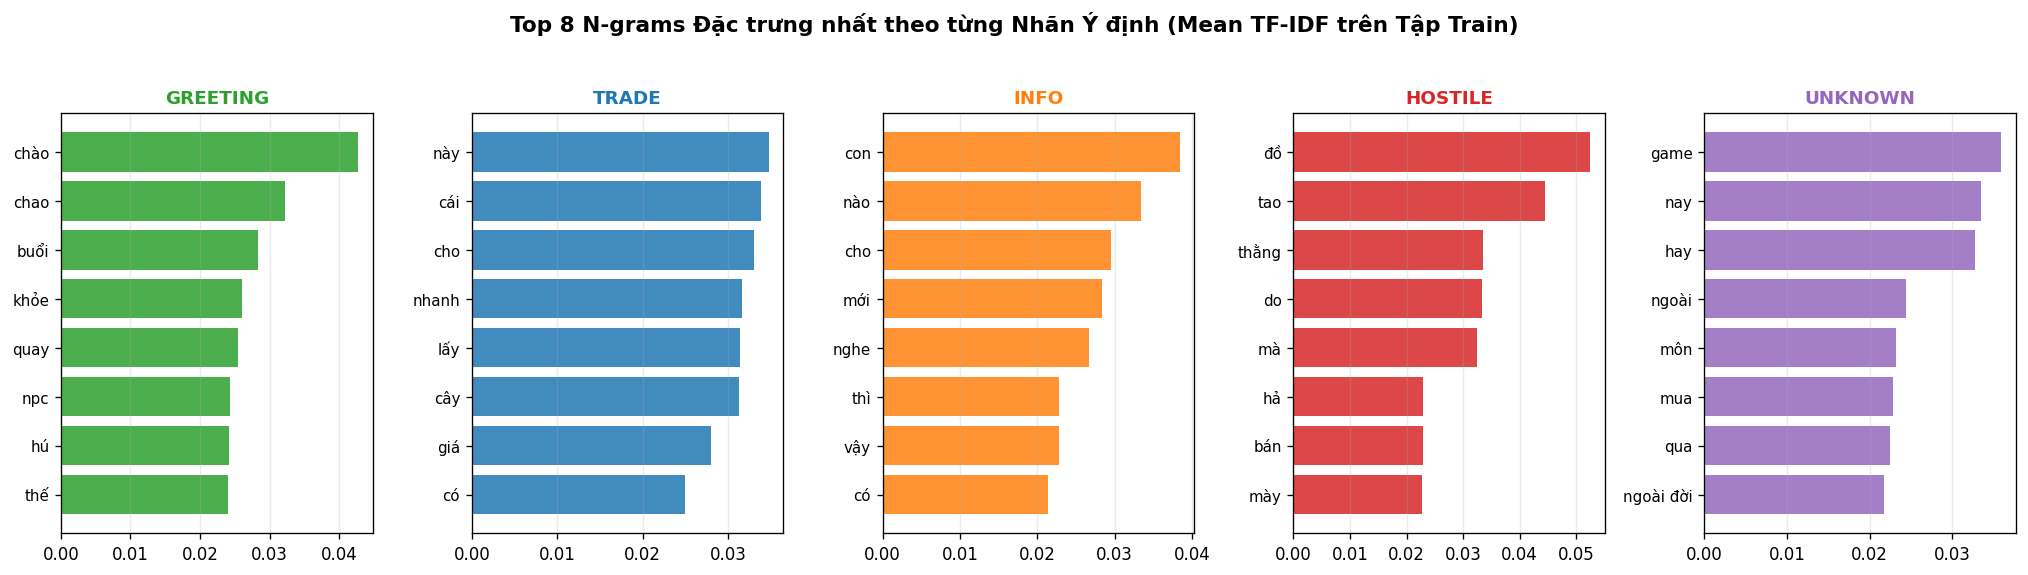

In [6]:
vectorizer = TfidfVectorizer(max_features=2000, ngram_range=(1, 2), sublinear_tf=True)
X_train_tfidf = vectorizer.fit_transform(df_train["text"])
X_test_tfidf = vectorizer.transform(df_test["text"])
vocab_terms = np.array(vectorizer.get_feature_names_out())

n_unigrams = sum(1 for t in vocab_terms if " " not in t)
n_bigrams = sum(1 for t in vocab_terms if " " in t)
train_density = X_train_tfidf.nnz / (X_train_tfidf.shape[0] * X_train_tfidf.shape[1]) * 100
avg_active_features = X_train_tfidf.nnz / X_train_tfidf.shape[0]

print(f"Kích thước ma trận X_train TF-IDF : {X_train_tfidf.shape} (Sparse CSR)")
print(f"Kích thước ma trận X_test TF-IDF  : {X_test_tfidf.shape} (Chỉ transform từ từ điển Train)")
print(f"Cấu trúc từ điển ({len(vocab_terms)} đặc trưng) : {n_unigrams} Unigrams ({n_unigrams/len(vocab_terms)*100:.1f}%) | {n_bigrams} Bigrams ({n_bigrams/len(vocab_terms)*100:.1f}%)")
print(f"Độ thưa ma trận (Sparsity)        : {100 - train_density:.2f}% (Trung bình {avg_active_features:.1f} đặc trưng khác 0 / câu)")

# Trực quan hóa Top 8 N-grams có trọng số TF-IDF trung bình cao nhất ở mỗi lớp Intent
fig, axes = plt.subplots(1, 5, figsize=(17, 4.6))
y_train_str = df_train["intent"].values

for idx, intent in enumerate(INTENT_NAMES):
    mask = y_train_str == intent
    mean_tfidf = np.asarray(X_train_tfidf[mask].mean(axis=0)).ravel()
    top_idx = np.argsort(mean_tfidf)[-8:]
    ax = axes[idx]
    ax.barh(vocab_terms[top_idx], mean_tfidf[top_idx], color=INTENT_COLORS[intent], alpha=0.85)
    ax.set_title(intent, fontsize=11, fontweight="bold", color=INTENT_COLORS[intent])
    ax.tick_params(axis="y", labelsize=9)
    ax.grid(axis="x", alpha=0.25)

fig.suptitle("Top 8 N-grams Đặc trưng nhất theo từng Nhãn Ý định (Mean TF-IDF trên Tập Train)", fontsize=13, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

## 6. Trực quan hóa Phân cụm Không gian Đặc trưng 2D (`TruncatedSVD`)
Để quan sát hình học của dữ liệu văn bản thưa 2.000 chiều, ta áp dụng `TruncatedSVD` (*Latent Semantic Analysis — LSA*) chiếu thẳng ma trận thưa `X_train_tfidf` xuống mặt phẳng 2 thành phần chính có phương sai lớn nhất và đối chiếu với phân phối tâm cụm của từng nhãn.

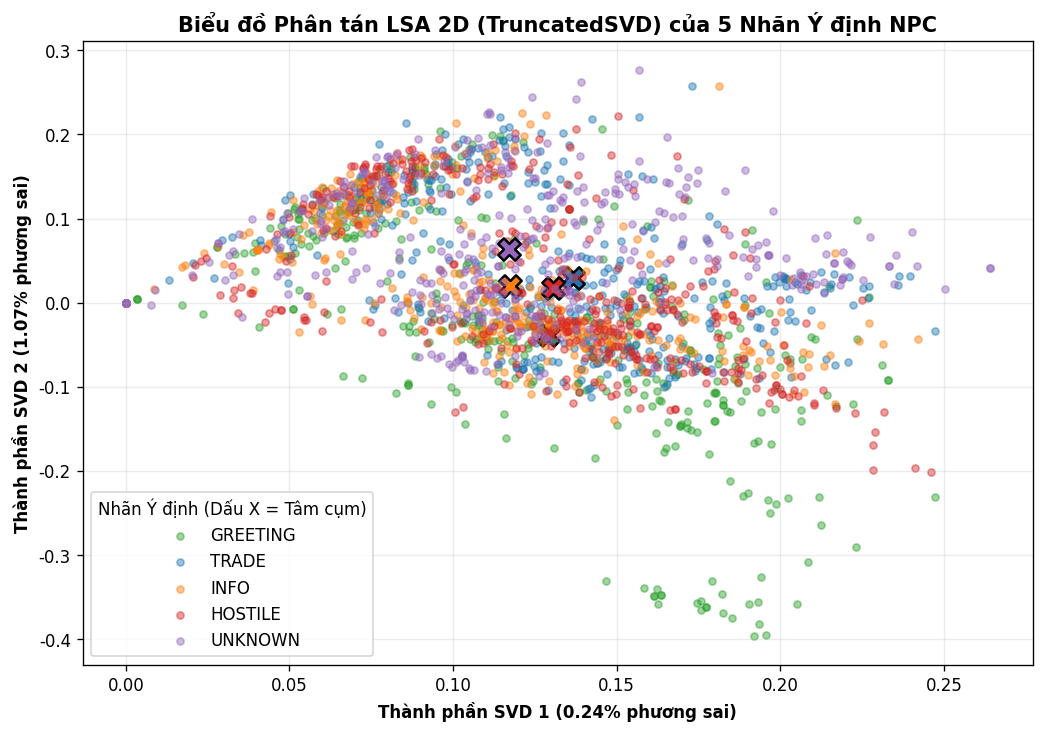

In [7]:
svd = TruncatedSVD(n_components=2, random_state=42)
X_2d = svd.fit_transform(X_train_tfidf)

rng = np.random.default_rng(42)
sample_indices = rng.choice(len(df_train), size=min(2000, len(df_train)), replace=False)

fig, ax = plt.subplots(figsize=(8.8, 6.2))
for intent in INTENT_NAMES:
    idx_sub = [i for i in sample_indices if y_train_str[i] == intent]
    pts = X_2d[idx_sub]
    ax.scatter(pts[:, 0], pts[:, 1], s=18, alpha=0.45, label=intent, color=INTENT_COLORS[intent])
    centroid = X_2d[y_train_str == intent].mean(axis=0)
    ax.scatter(centroid[0], centroid[1], s=180, marker="X", color=INTENT_COLORS[intent], edgecolor="black", linewidth=1.5)

ax.set_title("Biểu đồ Phân tán LSA 2D (TruncatedSVD) của 5 Nhãn Ý định NPC", fontsize=12.5, fontweight="bold")
ax.set_xlabel(f"Thành phần SVD 1 ({svd.explained_variance_ratio_[0]*100:.2f}% phương sai)", fontweight="bold")
ax.set_ylabel(f"Thành phần SVD 2 ({svd.explained_variance_ratio_[1]*100:.2f}% phương sai)", fontweight="bold")
ax.legend(title="Nhãn Ý định (Dấu X = Tâm cụm)", loc="best")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 7. Tổng kết Khám phá Dữ liệu & Định hướng Mô hình hóa
Từ kết quả phân tích trên, ta rút ra các nhận định nền tảng cho giai đoạn **Modeling**:
1. **Dữ liệu cân bằng rất tốt (~20% mỗi lớp)** trên cả tập Train và tập Test, cho phép sử dụng đồng thời **Accuracy** và **Macro F1-Score** làm thước đo chuẩn xác mà không cần kỹ thuật oversampling nhân tạo.
2. **Độ thưa cao (~99%) kèm hiện tượng chia sẻ thực thể (*Hard Negatives*)**: Các câu `INFO`, `TRADE` và `HOSTILE` thường dùng chung tên vật phẩm/địa danh (ví dụ `"kiếm sắt"`, `"hang nhện"`). Do đó:
   - Các mô hình xác suất dựa trên tần suất đồng xuất hiện toàn cục như **Multinomial Naive Bayes** hoặc các mô hình kết hợp phi tuyến đặc trưng bậc cao như **PyTorch MLP (`ReLU` / `SiLU`)** có tiềm năng phân tách tốt các mẫu giao thoa này.
3. **Bước tiếp theo**: Chuyển sang thư mục `Modeling/` để huấn luyện, tinh chỉnh siêu tham số và đối sánh toàn diện các mô hình Học máy kinh điển và Mạng nơ-ron sâu.